# Gengres data analysis

In [21]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns

df_genres = pd.read_csv('../data/genres.csv')
df_genres.head()

,id,genre
0,1000001,Comedy
1,1000001,Adventure
2,1000002,Comedy
3,1000002,Thriller
4,1000002,Drama


In [22]:
df_genres.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1046849 entries, 0 to 1046848
Data columns (total 2 columns):
 #   Column  Non-Null Count    Dtype 
---  ------  --------------    ----- 
 0   id      1046849 non-null  int64 
 1   genre   1046849 non-null  object
dtypes: int64(1), object(1)
memory usage: 16.0+ MB


In [23]:
df_genres.describe()

,id
count,1.046849e+06
mean,1.375578e+06
std,2.653416e+05
min,1.000001e+06
25%,1.139983e+06
50%,1.336303e+06
75%,1.589497e+06
max,1.941596e+06


In [24]:
df_genres.dtypes

id        int64
genre    object
dtype: object

- creatre a new column with the number of movies for each genre

In [25]:
df_genres['genre'].value_counts()

genre
Drama              232201
Documentary        163890
Comedy             140636
Animation           58708
Horror              53870
Romance             51549
Thriller            46726
Music               44105
Action              41695
Crime               35507
Family              27511
TV Movie            25874
Adventure           23093
Fantasy             22280
Mystery             21394
Science Fiction     21209
History             17008
War                 10758
Western              8835
Name: count, dtype: int64

-Visualize the distribution of the genres using a pie chart and a bar chart

<Axes: ylabel='count'>

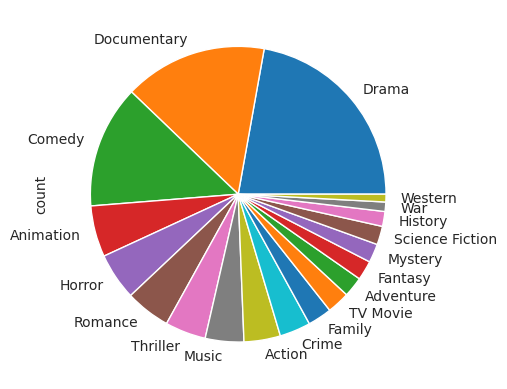

In [26]:
df_genres['genre'].value_counts().plot(kind='pie')

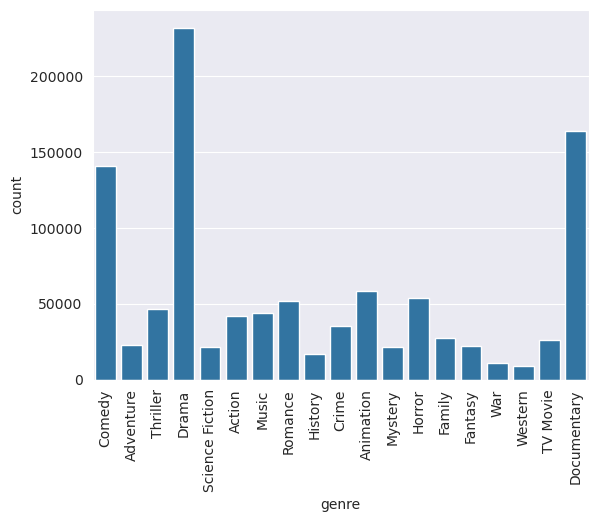

In [27]:
df_movies = pd.read_csv('../data/movies.csv')
df_movies_genres = pd.merge(df_movies, df_genres, on='id')
df_movies_genres.head()

sns.countplot(data=df_movies_genres, x='genre')
plt.xticks(rotation=90)
plt.show()

- We want to see the distribution of the rating for each genre, a boxplot is a good way to do this

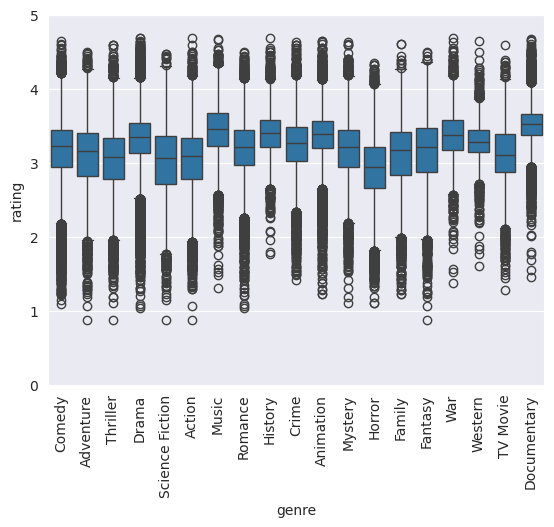

In [28]:
sns.boxplot(data=df_movies_genres, x='genre', y='rating')
plt.xticks(rotation=90)
plt.ylim(0, 5)
plt.show()

- we can use a countplot to see the number of movies for each rating

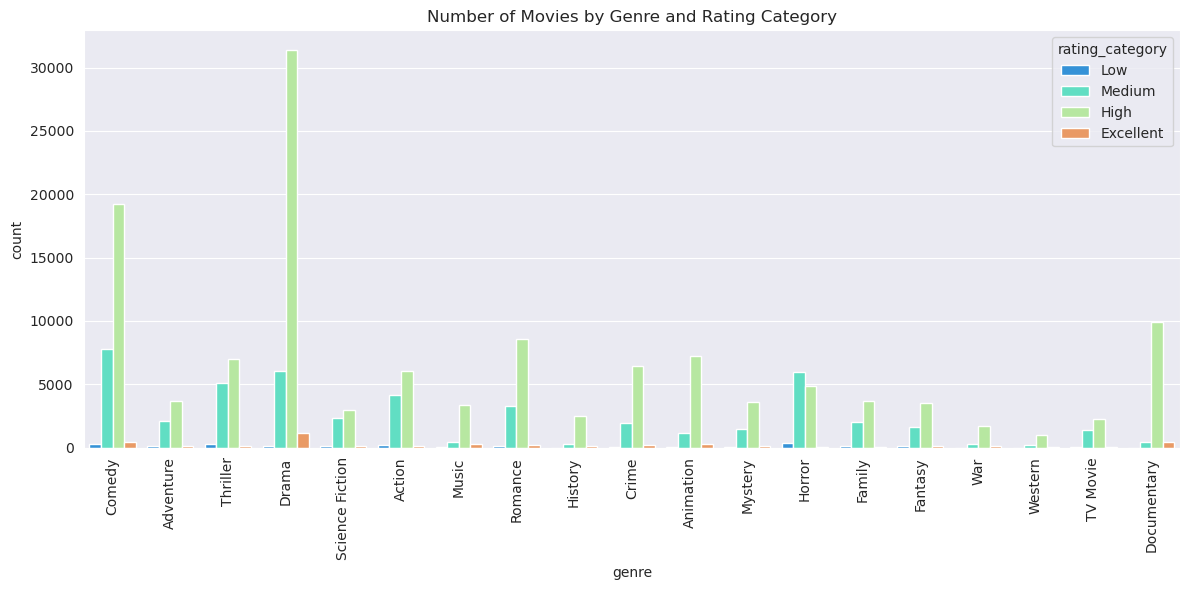

In [29]:
df_movies_genres['rating_category'] = pd.cut(
    df_movies_genres['rating'],
    bins=[0, 2, 3, 4, 5],
    labels=['Low', 'Medium', 'High', 'Excellent']
)

plt.figure(figsize=(12, 6))
sns.countplot(data=df_movies_genres, x='genre', hue='rating_category', palette='rainbow')
plt.xticks(rotation=90)
plt.title("Number of Movies by Genre and Rating Category")
plt.tight_layout()
plt.show()